# Neural Network (3-layer MLP) — PM2.5 Forecasting

**Model class (iv): complex, time-consuming.** Input layer → one hidden layer (ReLU) → one output (PM2.5 µg/m³).
One model is trained **per location** (6 cities, 12 Beijing stations) **per horizon** (1, 6, 24 h), with several random seeds.

In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import torch, torch.nn as nn
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)

# ------------------------------- CONFIG --------------------------------------
PROCESSED_DIR = "processed"
RESULTS_DIR   = "results/nn"
HORIZONS      = [1, 6, 24]
TARGETS       = {h: f"PM25_{h}hr_ahead" for h in HORIZONS}

SEEDS         = [0, 1, 2, 3, 4]      # report mean +/- sd across seeds
VAL_FRACTION  = 0.15                 # last 15% of each location's training period
MAX_EPOCHS    = 150
PATIENCE      = 15                   # early stopping on validation loss
BATCH_SIZE    = 256
LR            = 1e-3

DO_TUNING     = True                 # small grid search on a few representative locations
TUNE_GRID     = {"hidden": [16, 32, 64, 128], "weight_decay": [0.0, 1e-4, 1e-3]}
TUNE_LOCS     = {"global": ["London", "Cairo"], "beijing": ["Dongsi", "Huairou"]}
DEFAULT_CFG   = {"hidden": 64, "weight_decay": 1e-4}   # used if DO_TUNING = False

PERM_REPEATS  = 5                    # shuffles per feature for permutation importance

# set NN_QUICK_TEST=1 for a fast smoke test (few seeds / epochs / locations)
QUICK_TEST = os.environ.get("NN_QUICK_TEST", "0") == "1"
if QUICK_TEST:
    SEEDS, MAX_EPOCHS, PERM_REPEATS = [0], 5, 2
    TUNE_GRID = {"hidden": [16, 32], "weight_decay": [0.0]}

# use the same color for each model in every figure (agree on these with the team)
MODEL_COLORS = {"Mean": "tab:gray", "Persistence": "tab:orange", "Neural Network": "tab:red"}

DEVICE = "cpu"
os.makedirs(RESULTS_DIR, exist_ok=True)
print("torch", torch.__version__, "| threads:", torch.get_num_threads(), "| quick test:", QUICK_TEST)

torch 2.15.0 | threads: 4 | quick test: False


## 1. Load processed data

In [2]:
def load_dataset(name, loc_col):
    X_tr = pd.read_csv(f"{PROCESSED_DIR}/X_{name}_train.csv")
    X_te = pd.read_csv(f"{PROCESSED_DIR}/X_{name}_test.csv")
    Y_tr = pd.read_csv(f"{PROCESSED_DIR}/Y_{name}_train.csv")
    Y_te = pd.read_csv(f"{PROCESSED_DIR}/Y_{name}_test.csv")
    tr_info_path = f"{PROCESSED_DIR}/{name}_train_info.csv"
    if not os.path.exists(tr_info_path):
        raise FileNotFoundError(
            f"{tr_info_path} not found. Add the export cell from data_processing_patch.py to the "
            "data notebook and re-run it; without it we cannot train per location.")
    info_tr = pd.read_csv(tr_info_path)
    info_te = pd.read_csv(f"{PROCESSED_DIR}/{name}_test_info.csv")
    for info in (info_tr, info_te):
        info["Date"] = pd.to_datetime(info["Date"])
    assert len(X_tr) == len(Y_tr) == len(info_tr) and len(X_te) == len(Y_te) == len(info_te)
    assert "PM2.5" in X_tr.columns, "current PM2.5 is needed (persistence baseline + input feature)"
    return dict(name=name, loc_col=loc_col, X_tr=X_tr, X_te=X_te, Y_tr=Y_tr, Y_te=Y_te,
                info_tr=info_tr, info_te=info_te, locations=sorted(info_tr[loc_col].unique()))

datasets = {"global": load_dataset("global", "City"),
            "beijing": load_dataset("beijing", "station")}

for k, ds in datasets.items():
    print(f"{k:8s} train {ds['X_tr'].shape}  test {ds['X_te'].shape}  locations: {len(ds['locations'])}")
    print("         features:", list(ds["X_tr"].columns))

global   train (39102, 14)  test (13104, 14)  locations: 6
         features: ['CO', 'NO2', 'SO2', 'O3', 'PM2.5', 'PM10', 'PM25_lag1', 'PM25_lag2', 'PM25_lag3', 'PM25_roll24', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos']
beijing  train (236547, 35)  test (79830, 35)  locations: 12
         features: ['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM', 'wd_E', 'wd_ENE', 'wd_ESE', 'wd_N', 'wd_NE', 'wd_NNE', 'wd_NNW', 'wd_NW', 'wd_S', 'wd_SE', 'wd_SSE', 'wd_SSW', 'wd_SW', 'wd_W', 'wd_WNW', 'wd_WSW', 'PM25_lag1', 'PM25_lag2', 'PM25_lag3', 'PM25_roll24', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos']


## 2. Per-location data, scaling and the model

`get_location_data` slices one city/station, orders it by time, and carves out a **chronological validation block** (last 15% of training) with a 24 h buffer so no training target overlaps the validation period.

In [3]:
def get_location_data(ds, loc):
    lc = ds["loc_col"]
    m_tr = (ds["info_tr"][lc] == loc).values
    m_te = (ds["info_te"][lc] == loc).values

    X_all = ds["X_tr"][m_tr].reset_index(drop=True)
    Y_all = ds["Y_tr"][m_tr].reset_index(drop=True)
    d_all = ds["info_tr"].loc[m_tr, "Date"].reset_index(drop=True)
    order = d_all.sort_values(kind="stable").index
    X_all, Y_all, d_all = X_all.loc[order].reset_index(drop=True), Y_all.loc[order].reset_index(drop=True), d_all.loc[order].reset_index(drop=True)

    n = len(X_all); n_val = int(round(n * VAL_FRACTION))
    is_val = np.arange(n) >= n - n_val
    val_start = d_all.iloc[n - n_val]
    is_tr = (d_all + pd.Timedelta(hours=24) < val_start).values & ~is_val   # 24 h buffer

    X_te = ds["X_te"][m_te].reset_index(drop=True)
    Y_te = ds["Y_te"][m_te].reset_index(drop=True)
    d_te = ds["info_te"].loc[m_te, "Date"].reset_index(drop=True)
    o = d_te.sort_values(kind="stable").index
    X_te, Y_te, d_te = X_te.loc[o].reset_index(drop=True), Y_te.loc[o].reset_index(drop=True), d_te.loc[o].reset_index(drop=True)

    return dict(loc=loc, features=list(X_all.columns),
                X_tr=X_all[is_tr], Y_tr=Y_all[is_tr], X_va=X_all[is_val], Y_va=Y_all[is_val],
                Y_train_full=Y_all, X_te=X_te, Y_te=Y_te, d_te=d_te)

In [4]:
class MLP(nn.Module):
    """3-layer network: input -> 1 hidden layer (ReLU) -> 1 output."""
    def __init__(self, d_in, hidden):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_in, hidden), nn.ReLU(), nn.Linear(hidden, 1))
    def forward(self, x):
        return self.net(x).squeeze(-1)

def _t(a):
    return torch.tensor(np.asarray(a), dtype=torch.float32, device=DEVICE)

def train_mlp(Xtr, ytr, Xva, yva, hidden, weight_decay, seed):
    torch.manual_seed(seed)
    gen = torch.Generator().manual_seed(seed)
    model = MLP(Xtr.shape[1], hidden).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=weight_decay)
    loss_fn = nn.MSELoss()
    Xt, yt, Xv, yv = _t(Xtr), _t(ytr), _t(Xva), _t(yva)
    best, best_state, bad, hist = float("inf"), None, 0, []
    for epoch in range(MAX_EPOCHS):
        model.train()
        perm = torch.randperm(len(Xt), generator=gen)
        for i in range(0, len(perm), BATCH_SIZE):
            idx = perm[i:i + BATCH_SIZE]
            opt.zero_grad()
            loss_fn(model(Xt[idx]), yt[idx]).backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            tr_loss = loss_fn(model(Xt), yt).item(); va_loss = loss_fn(model(Xv), yv).item()
        hist.append((tr_loss, va_loss))
        if va_loss < best - 1e-6:
            best, bad = va_loss, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE:
                break
    model.load_state_dict(best_state)
    model.eval()
    return model, hist

def metrics(y, p):
    return dict(r2=r2_score(y, p), rmse=float(np.sqrt(mean_squared_error(y, p))), mae=mean_absolute_error(y, p))

def fit_location_horizon(L, horizon, hidden, weight_decay, seed):
    """Fit scalers on the training portion only, train, and return a predict function (original units)."""
    t = TARGETS[horizon]
    sx = StandardScaler().fit(L["X_tr"])
    y_tr = L["Y_tr"][t].values
    ym, ys = y_tr.mean(), y_tr.std() + 1e-8
    model, hist = train_mlp(sx.transform(L["X_tr"]), (y_tr - ym) / ys,
                            sx.transform(L["X_va"]), (L["Y_va"][t].values - ym) / ys,
                            hidden, weight_decay, seed)
    def predict(X_scaled):
        with torch.no_grad():
            return np.clip(model(_t(X_scaled)).numpy() * ys + ym, 0, None)   # PM2.5 cannot be negative
    return dict(model=model, scaler=sx, predict=predict, hist=hist)

## 3. Hyperparameter tuning (small, shared per dataset)

Tuning all 54 models separately would be slow and would overfit validation noise, so we grid-search on a few representative locations at all three horizons with one seed, and pick the setting with the best **mean validation R²**. The test set is not used.

In [5]:
def tune(ds_key):
    ds = datasets[ds_key]
    locs = [l for l in TUNE_LOCS[ds_key] if l in ds["locations"]] or ds["locations"][:2]
    cache = {l: get_location_data(ds, l) for l in locs}
    rows = []
    for hidden in TUNE_GRID["hidden"]:
        for wd in TUNE_GRID["weight_decay"]:
            scores = []
            for l in locs:
                L = cache[l]
                for h in HORIZONS:
                    f = fit_location_horizon(L, h, hidden, wd, seed=0)
                    p = f["predict"](f["scaler"].transform(L["X_va"]))
                    scores.append(r2_score(L["Y_va"][TARGETS[h]], p))
            rows.append(dict(hidden=hidden, weight_decay=wd, mean_val_r2=np.mean(scores)))
            print(f"  [{ds_key}] hidden={hidden:<4} wd={wd:<7} mean val R2 = {np.mean(scores):.4f}")
    res = pd.DataFrame(rows).sort_values("mean_val_r2", ascending=False)
    res.to_csv(f"{RESULTS_DIR}/tuning_{ds_key}.csv", index=False)
    best = res.iloc[0]
    return {"hidden": int(best["hidden"]), "weight_decay": float(best["weight_decay"])}, res

CONFIG = {}
t0 = time.time()
for k in datasets:
    if DO_TUNING:
        CONFIG[k], _ = tune(k)
    else:
        CONFIG[k] = dict(DEFAULT_CFG)
    print(f"-> {k}: chosen config {CONFIG[k]}")
print(f"Tuning took {time.time()-t0:.0f}s")

  [global] hidden=16   wd=0.0     mean val R2 = 0.5632
  [global] hidden=16   wd=0.0001  mean val R2 = 0.5632
  [global] hidden=16   wd=0.001   mean val R2 = 0.5639
  [global] hidden=32   wd=0.0     mean val R2 = 0.5560
  [global] hidden=32   wd=0.0001  mean val R2 = 0.5564
  [global] hidden=32   wd=0.001   mean val R2 = 0.5575
  [global] hidden=64   wd=0.0     mean val R2 = 0.5624
  [global] hidden=64   wd=0.0001  mean val R2 = 0.5625
  [global] hidden=64   wd=0.001   mean val R2 = 0.5634
  [global] hidden=128  wd=0.0     mean val R2 = 0.5832
  [global] hidden=128  wd=0.0001  mean val R2 = 0.5831
  [global] hidden=128  wd=0.001   mean val R2 = 0.5841
-> global: chosen config {'hidden': 128, 'weight_decay': 0.001}
  [beijing] hidden=16   wd=0.0     mean val R2 = 0.6145
  [beijing] hidden=16   wd=0.0001  mean val R2 = 0.6145
  [beijing] hidden=16   wd=0.001   mean val R2 = 0.6149
  [beijing] hidden=32   wd=0.0     mean val R2 = 0.6132
  [beijing] hidden=32   wd=0.0001  mean val R2 = 0.6

## 4. Train and evaluate every location × horizon × seed

Baselines (mean model, persistence) are scored here on exactly the same test rows so the NN table is self-contained. Metrics are in **µg/m³** on the held-out test period. Seed 0's model is also used for permutation importance.

In [6]:
def feature_groups(cols):
    """Shuffle related columns together (one-hot wind dummies, sin/cos pairs)."""
    groups = {}
    for c in cols:
        if c.startswith("wd_"):                 groups.setdefault("wind_direction", []).append(c)
        elif c in ("hour_sin", "hour_cos"):     groups.setdefault("hour_of_day", []).append(c)
        elif c in ("month_sin", "month_cos"):   groups.setdefault("month", []).append(c)
        else:                                   groups[c] = [c]
    return groups

def permutation_importance(fit, L, horizon, rng):
    Xs = fit["scaler"].transform(L["X_te"]); y = L["Y_te"][TARGETS[horizon]].values
    base = np.sqrt(mean_squared_error(y, fit["predict"](Xs)))
    out = []
    for g, cols in feature_groups(L["features"]).items():
        idx = [L["features"].index(c) for c in cols]
        incs = []
        for _ in range(PERM_REPEATS):
            Xp = Xs.copy(); perm = rng.permutation(len(Xp))
            Xp[:, idx] = Xs[perm][:, idx]
            incs.append(np.sqrt(mean_squared_error(y, fit["predict"](Xp))) - base)
        out.append(dict(feature=g, rmse_increase=np.mean(incs), rmse_increase_sd=np.std(incs)))
    return out

all_rows, pred_frames, imp_rows, curves = [], [], [], {}
t0 = time.time()
for k, ds in datasets.items():
    locs = ds["locations"][:2] if QUICK_TEST else ds["locations"]
    for loc in locs:
        L = get_location_data(ds, loc)
        Xte_raw = L["X_te"]
        for h in HORIZONS:
            t = TARGETS[h]; y_te = L["Y_te"][t].values
            # ---- baselines
            mean_pred = np.full(len(y_te), L["Y_train_full"][t].mean())
            pers_pred = Xte_raw["PM2.5"].values
            for name, p in [("Mean", mean_pred), ("Persistence", pers_pred)]:
                all_rows.append(dict(dataset=k, location=loc, horizon=h, model=name, seed=-1, **metrics(y_te, p)))
            # ---- neural network, several seeds
            seed_preds = []
            for s in SEEDS:
                f = fit_location_horizon(L, h, CONFIG[k]["hidden"], CONFIG[k]["weight_decay"], s)
                p = f["predict"](f["scaler"].transform(Xte_raw)); seed_preds.append(p)
                all_rows.append(dict(dataset=k, location=loc, horizon=h, model="Neural Network", seed=s,
                                     epochs=len(f["hist"]), **metrics(y_te, p)))
                if s == SEEDS[0]:
                    curves[(k, loc, h)] = f["hist"]
                    for r in permutation_importance(f, L, h, np.random.default_rng(0)):
                        imp_rows.append(dict(dataset=k, location=loc, horizon=h, **r))
            pred_frames.append(pd.DataFrame(dict(dataset=k, location=loc, horizon=h, Date=L["d_te"], actual=y_te,
                                                 nn_pred=np.mean(seed_preds, axis=0), persistence_pred=pers_pred,
                                                 mean_pred=mean_pred)))
        print(f"[{k}] {loc:<14s} done  ({time.time()-t0:.0f}s elapsed)")

results = pd.DataFrame(all_rows)
predictions = pd.concat(pred_frames, ignore_index=True)
importance = pd.DataFrame(imp_rows)
results.to_csv(f"{RESULTS_DIR}/nn_all_runs.csv", index=False)
predictions.to_csv(f"{RESULTS_DIR}/nn_test_predictions.csv", index=False)
importance.to_csv(f"{RESULTS_DIR}/nn_permutation_importance.csv", index=False)
print("Saved to", RESULTS_DIR)

[global] Brasilia       done  (2s elapsed)
[global] Cairo          done  (5s elapsed)
[global] Dubai          done  (8s elapsed)
[global] London         done  (11s elapsed)
[global] New York       done  (15s elapsed)
[global] Sydney         done  (17s elapsed)
[beijing] Aotizhongxin   done  (23s elapsed)
[beijing] Changping      done  (29s elapsed)
[beijing] Dingling       done  (36s elapsed)
[beijing] Dongsi         done  (43s elapsed)
[beijing] Guanyuan       done  (50s elapsed)
[beijing] Gucheng        done  (58s elapsed)
[beijing] Huairou        done  (63s elapsed)
[beijing] Nongzhanguan   done  (71s elapsed)
[beijing] Shunyi         done  (79s elapsed)
[beijing] Tiantan        done  (89s elapsed)
[beijing] Wanliu         done  (96s elapsed)
[beijing] Wanshouxigong  done  (105s elapsed)
Saved to results/nn


## 5. Quality-of-fit table (mean ± sd across seeds)

In [7]:
g = results.groupby(["dataset", "location", "horizon", "model"])[["r2", "rmse", "mae"]]
summary = g.mean().join(g.std().fillna(0).add_suffix("_sd")).reset_index()
summary["model"] = pd.Categorical(summary["model"], ["Mean", "Persistence", "Neural Network"], ordered=True)
summary = summary.sort_values(["dataset", "location", "horizon", "model"]).reset_index(drop=True)
summary.to_csv(f"{RESULTS_DIR}/nn_summary.csv", index=False)
pd.set_option("display.float_format", lambda v: f"{v:.3f}")
summary

,dataset,location,horizon,model,r2,rmse,mae,r2_sd,rmse_sd,mae_sd
0,beijing,Aotizhongxin,1,Mean,-0.000,87.561,63.808,0.000,0.000,0.000
1,beijing,Aotizhongxin,1,Persistence,0.948,19.898,10.734,0.000,0.000,0.000
2,beijing,Aotizhongxin,1,Neural Network,0.955,18.577,10.537,0.001,0.238,0.066
3,beijing,Aotizhongxin,6,Mean,-0.000,87.820,63.703,0.000,0.000,0.000
4,beijing,Aotizhongxin,6,Persistence,0.557,58.470,34.045,0.000,0.000,0.000
...,...,...,...,...,...,...,...,...,...,...
157,global,Sydney,6,Persistence,-0.175,4.795,3.349,0.000,0.000,0.000
158,global,Sydney,6,Neural Network,0.138,4.106,2.952,0.026,0.062,0.070
159,global,Sydney,24,Mean,-0.081,4.592,3.489,0.000,0.000,0.000
160,global,Sydney,24,Persistence,-0.703,5.762,4.148,0.000,0.000,0.000


In [8]:
# average over locations: how does accuracy fall from 1 h to 24 h, and does NN beat the baselines?
by_h = (summary.groupby(["dataset", "horizon", "model"], observed=True)[["r2", "rmse", "mae"]].mean().round(3))
by_h

r2   rmse    mae
dataset horizon model                              
beijing 1       Mean           -0.003 81.781 59.625
                Persistence     0.946 18.874 10.047
                Neural Network  0.954 17.500  9.923
        6       Mean           -0.003 81.948 59.560
                Persistence     0.563 54.154 31.675
                Neural Network  0.642 48.966 30.069
        24      Mean           -0.003 81.357 59.464
                Persistence    -0.136 86.476 57.255
                Neural Network  0.225 71.461 50.076
global  1       Mean           -0.082  8.122  6.593
                Persistence     0.896  2.402  1.534
                Neural Network  0.898  2.357  1.580
        6       Mean           -0.083  8.126  6.599
                Persistence     0.074  7.341  5.318
                Neural Network  0.316  6.367  4.744
        24      Mean           -0.087  8.146  6.617
                Persistence    -0.202  8.215  5.884
                Neural Network  0.032  7.491  5.686

In [9]:
# share of locations where the NN beats persistence (lower RMSE)
piv = summary.pivot_table(index=["dataset", "location", "horizon"], columns="model", values="rmse", observed=True)
piv["nn_beats_persistence"] = piv["Neural Network"] < piv["Persistence"]
piv["rmse_improvement_vs_persistence_%"] = 100 * (piv["Persistence"] - piv["Neural Network"]) / piv["Persistence"]
piv.groupby(["dataset", "horizon"])[["nn_beats_persistence", "rmse_improvement_vs_persistence_%"]].mean()

model            nn_beats_persistence  rmse_improvement_vs_persistence_%
dataset horizon                                                         
beijing 1                       1.000                              7.278
        6                       1.000                              9.471
        24                      1.000                             17.362
global  1                       0.667                              2.198
        6                       1.000                             13.990
        24                      1.000                              9.186

## 6. Figures

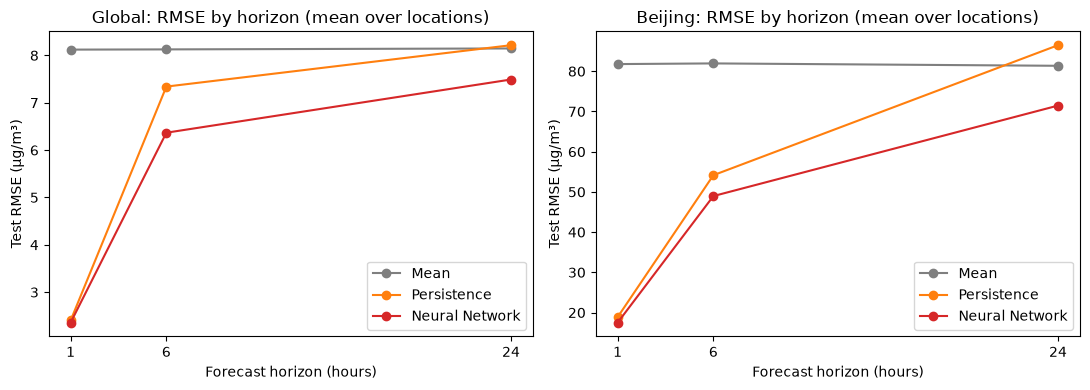

In [10]:
# Figure 1: RMSE vs horizon, averaged over locations
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, k in zip(axes, ["global", "beijing"]):
    d = summary[summary.dataset == k].groupby(["horizon", "model"], observed=True)["rmse"].mean().unstack()
    for m in d.columns:
        ax.plot(d.index, d[m], marker="o", label=m, color=MODEL_COLORS[m])
    ax.set_xticks(HORIZONS); ax.set_xlabel("Forecast horizon (hours)"); ax.set_ylabel("Test RMSE (µg/m³)")
    ax.set_title(f"{k.title()}: RMSE by horizon (mean over locations)"); ax.legend()
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/fig_rmse_by_horizon.png", dpi=150); plt.show()

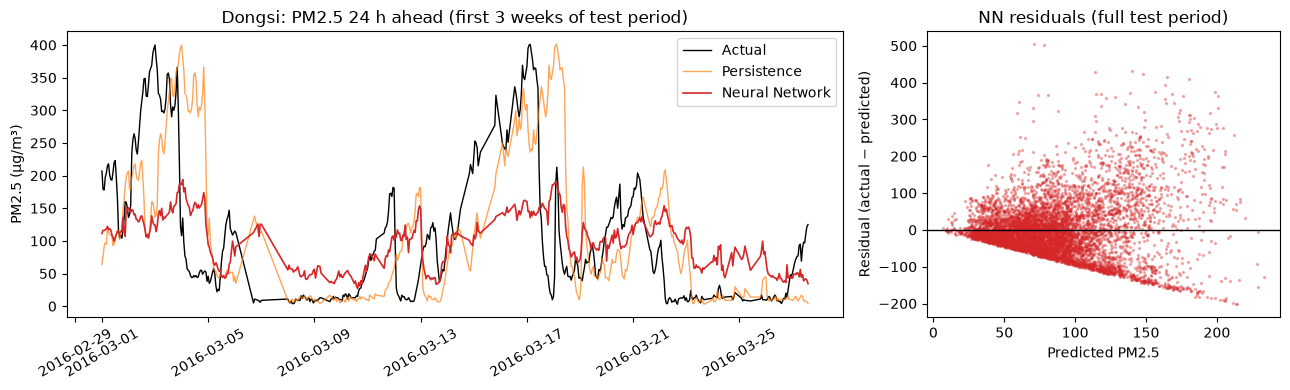

In [11]:
# Figure 2: predicted vs actual over time + residuals for one example location/horizon
EX_DS, EX_H = "beijing", 24
EX_LOC = "Dongsi" if "Dongsi" in datasets[EX_DS]["locations"] else datasets[EX_DS]["locations"][0]
d = predictions[(predictions.dataset == EX_DS) & (predictions.location == EX_LOC) & (predictions.horizon == EX_H)]
fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [2.2, 1]})
w = d.iloc[:24 * 21]   # first three weeks of the test period
axes[0].plot(w["Date"], w["actual"], color="black", lw=1, label="Actual")
axes[0].plot(w["Date"], w["persistence_pred"], color=MODEL_COLORS["Persistence"], lw=1, alpha=.7, label="Persistence")
axes[0].plot(w["Date"], w["nn_pred"], color=MODEL_COLORS["Neural Network"], lw=1.2, label="Neural Network")
axes[0].set_title(f"{EX_LOC}: PM2.5 {EX_H} h ahead (first 3 weeks of test period)"); axes[0].set_ylabel("PM2.5 (µg/m³)"); axes[0].legend()
axes[0].tick_params(axis="x", rotation=30)
axes[1].scatter(d["nn_pred"], d["actual"] - d["nn_pred"], s=2, alpha=.3, color=MODEL_COLORS["Neural Network"])
axes[1].axhline(0, color="black", lw=1); axes[1].set_xlabel("Predicted PM2.5"); axes[1].set_ylabel("Residual (actual − predicted)")
axes[1].set_title("NN residuals (full test period)")
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/fig_pred_vs_actual_example.png", dpi=150); plt.show()

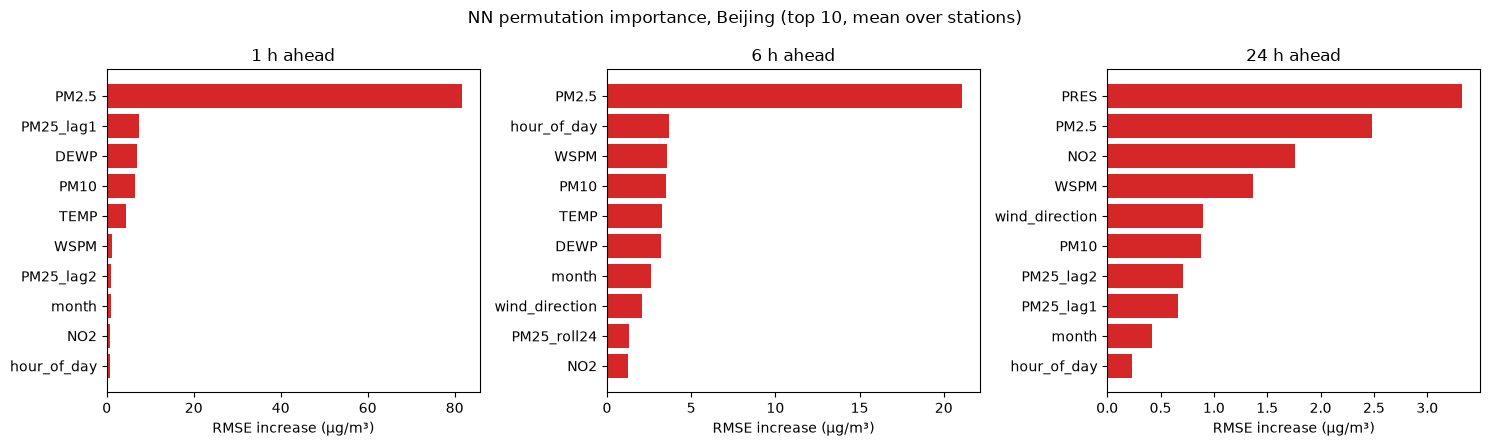

horizon                    1      6      24
dataset feature                            
beijing PRES            0.040  0.392  3.328
        PM2.5          81.639 21.084  2.485
        NO2             0.753  1.242  1.763
        WSPM            1.127  3.572  1.366
        wind_direction  0.648  2.069  0.901
        PM10            6.393  3.529  0.882
        PM25_lag2       1.087  0.388  0.713
        PM25_lag1       7.343  1.146  0.660
        month           0.885  2.645  0.423
        hour_of_day     0.721  3.659  0.237
global  PM2.5           7.817  0.435  0.199
beijing O3              0.209  0.496  0.182
        TEMP            4.537  3.250  0.181
        DEWP            6.980  3.221  0.129
global  SO2             0.102  0.007  0.071
        CO              0.388  0.097  0.062
        hour_of_day     0.180  0.552  0.051
beijing SO2             0.312  0.372  0.044
        RAIN            0.251  0.202  0.043
global  O3              0.047  0.068  0.033
beijing PM25_lag3       0.470  0.212  0.021
        PM25_roll24     0.423  1.311  0.018
global  PM25_lag2       0.087 -0.005  0.011
        month           0.003 -0.026  0.000
        NO2             0.105  0.012 -0.009

In [12]:
# Figure 3: permutation importance (RMSE increase when a feature group is shuffled), averaged over locations
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=False)
for ax, h in zip(axes, HORIZONS):
    d = importance[(importance.dataset == "beijing") & (importance.horizon == h)]
    if d.empty: d = importance[importance.horizon == h]
    top = d.groupby("feature")["rmse_increase"].mean().sort_values().tail(10)
    ax.barh(top.index, top.values, color=MODEL_COLORS["Neural Network"])
    ax.set_title(f"{h} h ahead"); ax.set_xlabel("RMSE increase (µg/m³)")
fig.suptitle("NN permutation importance, Beijing (top 10, mean over stations)")
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/fig_permutation_importance.png", dpi=150); plt.show()

# also the full table for the report
imp_table = importance.groupby(["dataset", "horizon", "feature"])["rmse_increase"].mean().unstack("horizon").round(3)
imp_table.sort_values(24, ascending=False).head(25)

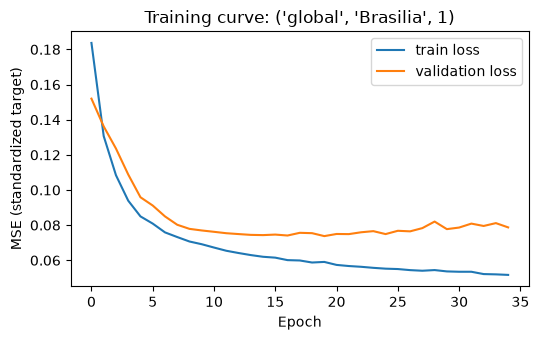

In [13]:
# Figure 4: training curves (sanity check for over/under-fitting) for one example model
key = next(iter(curves)); hist = np.array(curves[key])
plt.figure(figsize=(5.5, 3.5)); plt.plot(hist[:, 0], label="train loss"); plt.plot(hist[:, 1], label="validation loss")
plt.xlabel("Epoch"); plt.ylabel("MSE (standardized target)"); plt.title(f"Training curve: {key}"); plt.legend()
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/fig_training_curve_example.png", dpi=150); plt.show()